# SAMS Vision: Safe and Unsafe Behaviour Classification

**Status: served live as a single-frame ResNet18 classifier** (`monitoring/services/behaviour_inference.py`).

SAMS (Smart Accident Monitoring System) watches a worker near a machine through person detection, PPE, distance, pose and fall detection. This notebook asks a broader question: can a single camera frame be classified directly as a safe or unsafe workplace behaviour? It trains six image classifiers, a stronger image model, and a video model on a public dataset, and measures how far whole-frame and whole-clip classification get. The live service loads the best **image** experiment at `models/vision/safe_unsafe/` (ResNet18 fine-tune): Go Live sends one frame at a time, so the video-clip winner stays research-only.

## Dataset

[Voxel51/Safe_and_Unsafe_Behaviours](https://huggingface.co/datasets/Voxel51/Safe_and_Unsafe_Behaviours): 691 short 1080p clips filmed in one industrial facility, with a published train/test split (566 / 125 clips). The eight classes form four contrasting pairs, each with a safe and an unsafe version of the same activity:

| Activity | SAFE | UNSAFE |
|---|---|---|
| Moving around the floor | Safe Walkway | Safe Walkway Violation |
| Working on equipment | Authorized Intervention | Unauthorized Intervention |
| Electrical panels | Closed Panel Cover | Opened Panel Cover |
| Moving loads | Safe Carrying | Carrying Overload with Forklift |

The classes are imbalanced: from 210 clips (Safe Walkway Violation) down to 30 (Safe Carrying).

## Method and reasoning

1. **Frames from clips.** Each clip contributes `MAX_FRAMES_PER_VIDEO` evenly spaced frames. Image models see one frame at a time; the video model sees all of a clip's frames at once, in order.
2. **Leakage-free splits.** All frames of a clip stay in one split. The published test clips are used only for the final measurement. Validation clips are drawn from the training clips, 15 % per class, so even the rarest class is represented.
3. **A ladder of experiments.** A small CNN trained from scratch sets the floor. Frozen ImageNet backbones (ResNet18, EfficientNet-B0, MobileNetV3-Small) test how far generic features go. Full fine-tuning (ResNet18) tests adapting the features to this domain. A robust variant (EfficientNet-B0 with class-weighted loss and strong augmentation) targets the class imbalance. ConvNeXt-Tiny at a higher resolution tests a modern backbone that keeps more detail. R(2+1)D-18, pretrained on Kinetics-400 human actions, tests whether motion across a clip separates behaviours that look alike in one frame.
4. **Clip-level decisions, selected on validation only.** A behaviour belongs to a clip, not to a frame, so image models average their class probabilities over a clip's frames, and every model is scored per clip. Each run keeps the epoch with the best validation clip macro-F1 and stops early when it stops improving. The winner is the experiment with the best validation clip macro-F1. Test metrics are reported for every experiment but never used to choose. Frame-level scores are still reported for the image models.
5. **Two levels of evaluation.** Eight-class macro-F1 measures how well the classifier tells the behaviours apart. Grouping the predictions into SAFE and UNSAFE measures what SAMS would actually use, and **unsafe recall** (the share of unsafe frames caught) is the headline safety number.

## Sections

| § | Content |
|---|---|
| 0 | Setup: paths, packages, configuration, helpers |
| 1 | Dataset metadata and class list |
| 2 | Exploratory data analysis |
| 3 | Frame extraction, cached on Drive |
| 4 | Data pipeline, models and training utilities; embedding check |
| 5 | Experiments |
| 6 | Comparison, promotion and SAFE/UNSAFE evaluation |
| 7 | Findings, limitations and relevance to SAMS |

## Outputs

| Path | Content |
|---|---|
| `models/vision/safe_unsafe/<experiment_id>/` | Weights, metadata, history, classification report and confusion matrix of each experiment |
| `models/vision/safe_unsafe/best.pt`, `metadata.json`, `model_card.md` | The promoted experiment |
| `results/vision/safe_unsafe/` | Every table as CSV and every chart as PNG |
| `datasets/vision/safe_unsafe/frames_*.zip` (Drive) | Extracted frames, so later sessions skip the video download |


## 0. Setup

### 0.1 Paths

In Colab, the dataset and extracted frames live on the VM's local disk (`/content/SAMS`) for fast reading during training. Models, results and the frame cache live on Google Drive (`MyDrive/SAMS`) so they survive the session. Locally, the repository root plays the role of Drive.

In [1]:
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    SAMS_ROOT = Path("/content/SAMS")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")
    here = Path.cwd().resolve()
    DRIVE_ROOT = next((p for p in (here, here.parent) if (p / "manage.py").exists()), Path("./SAMS_drive_mirror"))

DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe"
SNAPSHOT_DIR = DATA_DIR / "hf_snapshot"
FRAMES_DIR = DATA_DIR / "frames"
CACHE_DIR = DRIVE_ROOT / "datasets" / "vision" / "safe_unsafe"
MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "safe_unsafe"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "safe_unsafe"
for folder in (DATA_DIR, SNAPSHOT_DIR, FRAMES_DIR, CACHE_DIR, MODELS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

for name in ("DATA_DIR", "CACHE_DIR", "MODELS_DIR", "RESULTS_DIR"):
    print(f"{name:12s}", globals()[name])

Running in Colab: True
Mounted at /content/drive
DATA_DIR     /content/SAMS/datasets/vision/safe_unsafe
CACHE_DIR    /content/drive/MyDrive/SAMS/datasets/vision/safe_unsafe
MODELS_DIR   /content/drive/MyDrive/SAMS/models/vision/safe_unsafe
RESULTS_DIR  /content/drive/MyDrive/SAMS/results/vision/safe_unsafe


### 0.2 Packages

In [2]:
import subprocess
import sys

PACKAGES = [
    "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "torch", "torchvision",
    "tqdm", "Pillow", "opencv-python-headless", "huggingface_hub",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("Packages installed.")
else:
    print("Not in Colab. Install these packages if an import fails:", PACKAGES)

Packages installed.


In [3]:
import gc
import json
import random
import shutil
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import display
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

### 0.3 Configuration

Every setting that changes the result is set here and listed with its meaning. Change a value and rerun from this cell downward.

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_REPO = "Voxel51/Safe_and_Unsafe_Behaviours"
MAX_FRAMES_PER_VIDEO = 8
FRAME_MAX_SIDE = 640
VAL_FRACTION = 0.15

IMG_SIZE = 224
IMG_SIZE_LARGE = 288
BATCH_SIZE = 32
BATCH_SIZE_LARGE = 16
NUM_WORKERS = 2
PATIENCE = 5

EPOCHS_SCRATCH = 12
EPOCHS_FROZEN = 8
EPOCHS_FINETUNE = 20
LR_HEAD = 1e-3
LR_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

VIDEO_SIZE = 160
VIDEO_BATCH_SIZE = 8
EPOCHS_VIDEO = 20
KINETICS_MEAN = [0.43216, 0.394666, 0.37645]
KINETICS_STD = [0.22803, 0.22145, 0.216989]

UNSAFE_CLASSES = {
    "Safe Walkway Violation",
    "Unauthorized Intervention",
    "Opened Panel Cover",
    "Carrying Overload with Forklift",
}
SAFE_CLASSES = {"Safe Walkway", "Authorized Intervention", "Closed Panel Cover", "Safe Carrying"}

config_table = pd.DataFrame([
    {"setting": "SEED", "value": SEED, "meaning": "Seed for Python, NumPy and PyTorch"},
    {"setting": "DEVICE", "value": str(DEVICE), "meaning": "Training device"},
    {"setting": "MAX_FRAMES_PER_VIDEO", "value": MAX_FRAMES_PER_VIDEO, "meaning": "Evenly spaced frames taken from each clip; the video model sees all of them as one clip"},
    {"setting": "FRAME_MAX_SIDE", "value": FRAME_MAX_SIDE, "meaning": "Longest side of a stored frame in pixels (1080p is downscaled)"},
    {"setting": "VAL_FRACTION", "value": VAL_FRACTION, "meaning": "Share of each class's training clips held out for validation"},
    {"setting": "IMG_SIZE", "value": IMG_SIZE, "meaning": "Image-model input size (square)"},
    {"setting": "IMG_SIZE_LARGE", "value": IMG_SIZE_LARGE, "meaning": "Input size for ConvNeXt-Tiny, which keeps more detail such as a panel cover"},
    {"setting": "BATCH_SIZE", "value": BATCH_SIZE, "meaning": "Frames per training step"},
    {"setting": "BATCH_SIZE_LARGE", "value": BATCH_SIZE_LARGE, "meaning": "Frames per step at IMG_SIZE_LARGE"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Epochs without a better validation clip macro-F1 before stopping"},
    {"setting": "EPOCHS_SCRATCH", "value": EPOCHS_SCRATCH, "meaning": "Epoch limit, CNN from scratch"},
    {"setting": "EPOCHS_FROZEN", "value": EPOCHS_FROZEN, "meaning": "Epoch limit, frozen backbones"},
    {"setting": "EPOCHS_FINETUNE", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit, full fine-tuning"},
    {"setting": "LR_HEAD", "value": LR_HEAD, "meaning": "AdamW learning rate when only a new head (or a small CNN) trains"},
    {"setting": "LR_FINETUNE", "value": LR_FINETUNE, "meaning": "AdamW learning rate when pretrained layers train too"},
    {"setting": "WEIGHT_DECAY", "value": WEIGHT_DECAY, "meaning": "AdamW weight decay"},
    {"setting": "LABEL_SMOOTHING", "value": LABEL_SMOOTHING, "meaning": "Label smoothing for the ConvNeXt and video experiments"},
    {"setting": "VIDEO_SIZE", "value": VIDEO_SIZE, "meaning": "Frame size for the video model"},
    {"setting": "VIDEO_BATCH_SIZE", "value": VIDEO_BATCH_SIZE, "meaning": "Clips per training step for the video model"},
    {"setting": "EPOCHS_VIDEO", "value": EPOCHS_VIDEO, "meaning": "Epoch limit, video model"},
]).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42,"Seed for Python, NumPy and PyTorch"
DEVICE,cuda,Training device
MAX_FRAMES_PER_VIDEO,8,Evenly spaced frames taken from each clip; the...
FRAME_MAX_SIDE,640,Longest side of a stored frame in pixels (1080...
VAL_FRACTION,0.15,Share of each class's training clips held out ...
IMG_SIZE,224,Image-model input size (square)
IMG_SIZE_LARGE,288,"Input size for ConvNeXt-Tiny, which keeps more..."
BATCH_SIZE,32,Frames per training step
BATCH_SIZE_LARGE,16,Frames per step at IMG_SIZE_LARGE


### 0.4 Helpers

In [5]:
def save_table(frame: pd.DataFrame, name: str) -> Path:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)
    return path


def save_figure(name: str) -> None:
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()


def to_json_safe(value):
    """Turn NumPy values into plain Python types that json can write."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Dataset metadata and class list

Only `samples.json` is downloaded here: it lists every clip with its label, split tag and video properties. The videos themselves (several GB) are needed only when frames have to be extracted (Section 3), so a session that finds the frame cache on Drive never downloads them.

In [6]:
from huggingface_hub import snapshot_download

snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=str(SNAPSHOT_DIR), allow_patterns=["samples.json"])
with open(SNAPSHOT_DIR / "samples.json") as f:
    samples_blob = json.load(f)
raw_samples = samples_blob["samples"] if isinstance(samples_blob, dict) else samples_blob

rows = []
for sample in raw_samples:
    tags = sample.get("tags") or []
    md_ = sample.get("metadata") or {}
    rows.append({
        "video": Path(sample["filepath"]).stem,
        "relpath": sample["filepath"],
        "label": (sample.get("ground_truth") or {}).get("label"),
        "split": "train" if "train" in tags else ("test" if "test" in tags else "unknown"),
        "duration_s": md_.get("duration"),
        "fps": md_.get("frame_rate"),
        "width": md_.get("frame_width"),
        "height": md_.get("frame_height"),
    })
meta_df = pd.DataFrame(rows)
meta_df = meta_df[meta_df["label"].notna() & meta_df["split"].isin(["train", "test"])].reset_index(drop=True)

CLASS_NAMES = sorted(meta_df["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
unknown = set(CLASS_NAMES) - UNSAFE_CLASSES - SAFE_CLASSES
assert not unknown, f"Classes missing from the SAFE/UNSAFE grouping: {unknown}"
UNSAFE_IDX = np.array([label_to_idx[c] for c in CLASS_NAMES if c in UNSAFE_CLASSES])
meta_df["group"] = np.where(meta_df["label"].isin(UNSAFE_CLASSES), "UNSAFE", "SAFE")

print("Clips:", len(meta_df), "| classes:", NUM_CLASSES)
save_table(
    pd.DataFrame({"class": CLASS_NAMES, "index": range(NUM_CLASSES), "group": ["UNSAFE" if c in UNSAFE_CLASSES else "SAFE" for c in CLASS_NAMES]}).set_index("class"),
    "class_list",
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Clips: 691 | classes: 8


,index,group
class,,
Authorized Intervention,0,SAFE
Carrying Overload with Forklift,1,UNSAFE
Closed Panel Cover,2,SAFE
Opened Panel Cover,3,UNSAFE
Safe Carrying,4,SAFE
Safe Walkway,5,SAFE
Safe Walkway Violation,6,UNSAFE
Unauthorized Intervention,7,UNSAFE


PosixPath('/content/drive/MyDrive/SAMS/results/vision/safe_unsafe/class_list.csv')

## 2. Exploratory data analysis

Clip counts per class and split, and clip durations. Two things matter for the experiments. First, the imbalance: the largest class has about seven times as many clips as the smallest, which is why selection uses macro-F1 (every class counts equally) rather than accuracy. Second, how few test clips the rare classes have: a class with 8 test clips gives 24 test frames, so its per-class scores move in large steps.

split,test,train,total,group
label,,,,
Safe Walkway Violation,32,178,210,UNSAFE
Opened Panel Cover,13,129,142,UNSAFE
Unauthorized Intervention,11,97,108,UNSAFE
Safe Walkway,25,50,75,SAFE
Carrying Overload with Forklift,8,48,56,UNSAFE
Authorized Intervention,15,23,38,SAFE
Closed Panel Cover,13,19,32,SAFE
Safe Carrying,8,22,30,SAFE


,mean,min,max
label,,,
Authorized Intervention,9.2,4.1,15.0
Carrying Overload with Forklift,6.9,3.0,13.0
Closed Panel Cover,4.9,1.4,10.5
Opened Panel Cover,5.8,2.6,12.0
Safe Carrying,7.4,2.1,12.1
Safe Walkway,9.5,4.0,20.8
Safe Walkway Violation,9.7,5.0,17.0
Unauthorized Intervention,10.3,7.0,20.8


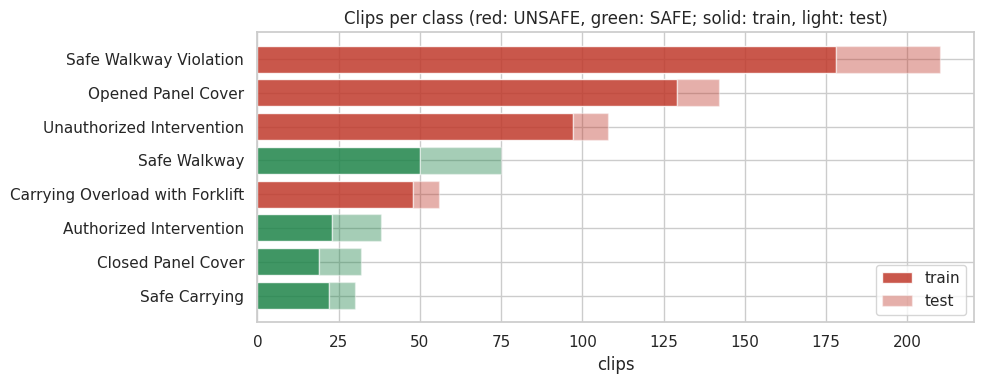

In [7]:
counts = pd.crosstab(meta_df["label"], meta_df["split"]).reindex(CLASS_NAMES)
counts["total"] = counts.sum(axis=1)
counts["group"] = ["UNSAFE" if c in UNSAFE_CLASSES else "SAFE" for c in counts.index]
save_table(counts.sort_values("total", ascending=False), "eda_clips_by_class_and_split")
save_table(meta_df.groupby("label")["duration_s"].describe()[["mean", "min", "max"]].round(1), "eda_clip_durations_s")

fig, ax = plt.subplots(figsize=(10, 4))
order = counts.sort_values("total", ascending=False).index
colors = ["#c0392b" if c in UNSAFE_CLASSES else "#1e8449" for c in order]
ax.barh(order, counts.loc[order, "train"], color=colors, alpha=0.85, label="train")
ax.barh(order, counts.loc[order, "test"], left=counts.loc[order, "train"], color=colors, alpha=0.4, label="test")
ax.invert_yaxis()
ax.set_xlabel("clips")
ax.set_title("Clips per class (red: UNSAFE, green: SAFE; solid: train, light: test)")
ax.legend()
save_figure("eda_clips_per_class")

## 3. Frame extraction

`MAX_FRAMES_PER_VIDEO` evenly spaced frames are taken from every clip, downscaled so the longest side is `FRAME_MAX_SIDE` pixels (the network sees 224 × 224 anyway), and written to `frames/<split>/<class>/`. A manifest records each frame's clip, label and split.

The frames are zipped to Drive. A later session restores them from the zip and never downloads the videos again. The zip's name includes the extraction settings, so changing a setting extracts the frames afresh.

In [8]:
FRAME_CACHE = CACHE_DIR / f"frames_{MAX_FRAMES_PER_VIDEO}x{FRAME_MAX_SIDE}.zip"
manifest_path = FRAMES_DIR / "manifest.csv"


def extract_frames(video_path: Path, out_dir: Path, stem: str) -> List[Path]:
    """Up to MAX_FRAMES_PER_VIDEO evenly spaced frames, longest side FRAME_MAX_SIDE."""
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if total <= 0:
        cap.release()
        return []
    out_dir.mkdir(parents=True, exist_ok=True)
    saved = []
    for j, index in enumerate(np.linspace(0, total - 1, num=min(MAX_FRAMES_PER_VIDEO, total), dtype=int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
        ok, frame = cap.read()
        if not ok:
            continue
        scale = FRAME_MAX_SIDE / max(frame.shape[:2])
        if scale < 1:
            frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        path = out_dir / f"{stem}_f{j:02d}.jpg"
        cv2.imwrite(str(path), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
        saved.append(path)
    cap.release()
    return saved


settings_path = FRAMES_DIR / "settings.json"
extraction_settings = {"frames_per_video": MAX_FRAMES_PER_VIDEO, "max_side": FRAME_MAX_SIDE}
if manifest_path.exists() and (not settings_path.exists() or json.loads(settings_path.read_text()) != extraction_settings):
    print("Frames from other extraction settings: extracting again.")
    shutil.rmtree(FRAMES_DIR)
    FRAMES_DIR.mkdir(parents=True)

if not manifest_path.exists() and FRAME_CACHE.exists():
    print("Restoring frames from", FRAME_CACHE)
    shutil.unpack_archive(str(FRAME_CACHE), str(FRAMES_DIR))

if not manifest_path.exists():
    print("No frame cache: downloading the videos (several GB) and extracting frames.")
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=str(SNAPSHOT_DIR), allow_patterns=["data/*"])
    records = []
    for row in tqdm(meta_df.itertuples(), total=len(meta_df), desc="Extracting"):
        out_dir = FRAMES_DIR / row.split / row.label.replace(" ", "_")
        for path in extract_frames(SNAPSHOT_DIR / row.relpath, out_dir, row.video):
            records.append({"relpath": str(path.relative_to(FRAMES_DIR)), "video": row.video, "split": row.split, "label": row.label})
    pd.DataFrame(records).to_csv(manifest_path, index=False)
    settings_path.write_text(json.dumps(extraction_settings))
    print("Caching frames to", FRAME_CACHE)
    shutil.make_archive(str(FRAME_CACHE.with_suffix("")), "zip", str(FRAMES_DIR))

frame_manifest = pd.read_csv(manifest_path)
frame_manifest["filepath"] = frame_manifest["relpath"].map(lambda p: str(FRAMES_DIR / p))
frame_manifest["label_idx"] = frame_manifest["label"].map(label_to_idx)
missing_clips = sorted(set(meta_df["video"]) - set(frame_manifest["video"]))
print(f"Frames: {len(frame_manifest)} from {frame_manifest['video'].nunique()} clips; clips with no readable frame: {len(missing_clips)}")
save_table(frame_manifest.groupby(["split", "label"]).size().unstack(0).reindex(CLASS_NAMES), "frames_by_class_and_split")

Restoring frames from /content/drive/MyDrive/SAMS/datasets/vision/safe_unsafe/frames_8x640.zip
Frames: 5514 from 691 clips; clips with no readable frame: 0


split,test,train
label,,
Authorized Intervention,120,183
Carrying Overload with Forklift,64,384
Closed Panel Cover,103,152
Opened Panel Cover,104,1032
Safe Carrying,64,176
Safe Walkway,198,398
Safe Walkway Violation,253,1420
Unauthorized Intervention,88,775


PosixPath('/content/drive/MyDrive/SAMS/results/vision/safe_unsafe/frames_by_class_and_split.csv')

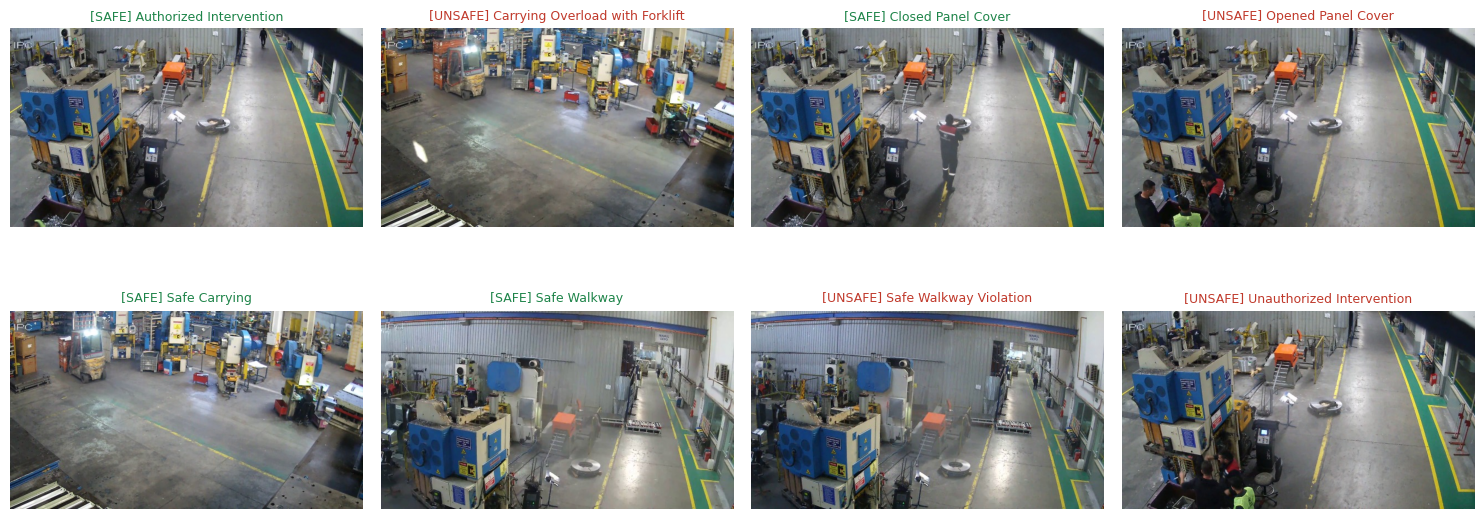

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, cls in zip(axes.ravel(), CLASS_NAMES):
    row = frame_manifest[(frame_manifest["label"] == cls) & (frame_manifest["split"] == "train")].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(row["filepath"]).convert("RGB"))
    unsafe = cls in UNSAFE_CLASSES
    ax.set_title(f"[{'UNSAFE' if unsafe else 'SAFE'}] {cls}", fontsize=9, color="#c0392b" if unsafe else "#1e8449")
    ax.axis("off")
save_figure("eda_class_gallery")

## 4. Data pipeline, models and training utilities

### 4.1 Splits and loaders

**Splits.** The published test clips form the test set. From the training clips, `VAL_FRACTION` of each class's clips (at least one) is held out for validation. All frames of a clip stay in the same split, so no near-identical frame can appear on both sides.

**Transforms.** Every frame is resized to 224 × 224 and normalised with the ImageNet statistics the pretrained backbones expect. Training adds a horizontal flip. The robust experiment uses stronger augmentation: random crops, colour jitter and small rotations, which imitate camera placement and lighting changes.

In [10]:
NORMALIZE = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tfms = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), NORMALIZE])
strong_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    NORMALIZE,
])
eval_tfms = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), NORMALIZE])


class FrameDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.paths = df["filepath"].tolist()
        self.labels = df["label_idx"].astype(int).tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        return self.transform(Image.open(self.paths[idx]).convert("RGB")), self.labels[idx]


def split_frames(manifest: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    """Test = published test clips. Validation = VAL_FRACTION of each class's training clips."""
    train_all = manifest[manifest["split"] == "train"]
    rng = np.random.default_rng(SEED)
    val_videos = set()
    for _cls, clips in train_all.groupby("label")["video"]:
        videos = sorted(clips.unique())
        n_val = max(1, int(round(VAL_FRACTION * len(videos))))
        val_videos.update(rng.choice(videos, size=n_val, replace=False))
    return {
        "train": train_all[~train_all["video"].isin(val_videos)].reset_index(drop=True),
        "val": train_all[train_all["video"].isin(val_videos)].reset_index(drop=True),
        "test": manifest[manifest["split"] == "test"].reset_index(drop=True),
    }


def make_loaders(frames: Dict[str, pd.DataFrame], train_transform, eval_transform=None, batch_size: int = BATCH_SIZE) -> Dict[str, DataLoader]:
    eval_transform = eval_tfms if eval_transform is None else eval_transform
    generator = torch.Generator().manual_seed(SEED)
    pin = torch.cuda.is_available()
    return {
        "train": DataLoader(FrameDataset(frames["train"], train_transform), batch_size=batch_size, shuffle=True,
                            generator=generator, num_workers=NUM_WORKERS, pin_memory=pin),
        "val": DataLoader(FrameDataset(frames["val"], eval_transform), batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
        "test": DataLoader(FrameDataset(frames["test"], eval_transform), batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
    }


FRAMES = split_frames(frame_manifest)
base_loaders = make_loaders(FRAMES, train_tfms)
split_table = pd.DataFrame({
    f"{split} {unit}": frame.groupby("label")["video"].nunique() if unit == "clips" else frame.groupby("label").size()
    for split, frame in FRAMES.items()
    for unit in ("clips", "frames")
}).reindex(CLASS_NAMES).fillna(0).astype(int)
split_table.loc["total"] = split_table.sum()
save_table(split_table, "split_by_class")
assert not (set(FRAMES["train"]["video"]) & set(FRAMES["val"]["video"])), "A clip is in both train and val"
FRAME_CLIPS = {split: frame["video"].to_numpy() for split, frame in FRAMES.items()}

,train clips,train frames,val clips,val frames,test clips,test frames
label,,,,,,
Authorized Intervention,20,159,3,24,15,120
Carrying Overload with Forklift,41,328,7,56,8,64
Closed Panel Cover,16,128,3,24,13,103
Opened Panel Cover,110,880,19,152,13,104
Safe Carrying,19,152,3,24,8,64
Safe Walkway,42,335,8,63,25,198
Safe Walkway Violation,151,1204,27,216,32,253
Unauthorized Intervention,82,655,15,120,11,88
total,481,3841,85,679,125,994


### 4.2 Embedding check

Before training, a frozen ImageNet ResNet18 embeds up to 20 training frames per class, and the embeddings are projected onto two principal components. Classes that already cluster here need little adaptation. Classes that overlap need the network to learn features specific to this domain, which is what fine-tuning offers.

/tmp/ipykernel_587/1148592011.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pca_frames = FRAMES["train"].groupby("label", group_keys=False).apply(lambda f: f.sample(min(20, len(f)), random_state=SEED))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


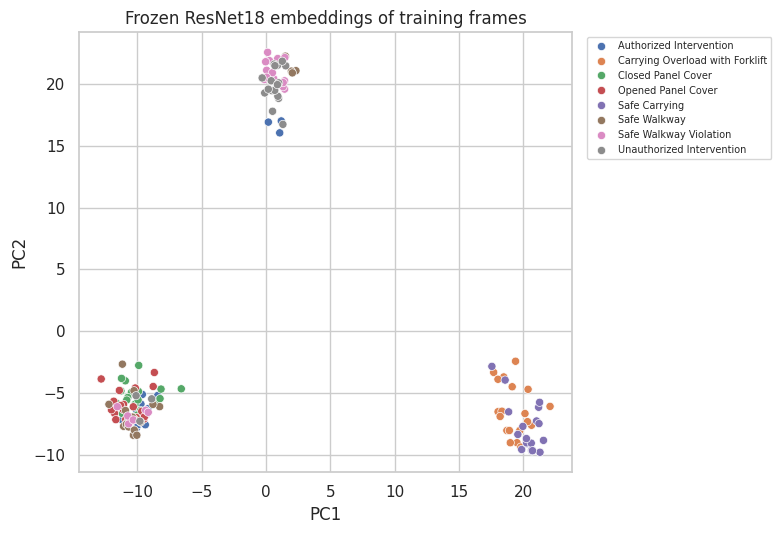

In [11]:
@torch.no_grad()
def embed_frames(paths: List[str]) -> np.ndarray:
    trunk = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    trunk.fc = nn.Identity()
    trunk = trunk.to(DEVICE).eval()
    vectors = []
    for start in range(0, len(paths), BATCH_SIZE):
        batch = torch.stack([eval_tfms(Image.open(p).convert("RGB")) for p in paths[start : start + BATCH_SIZE]])
        vectors.append(trunk(batch.to(DEVICE)).cpu().numpy())
    return np.concatenate(vectors)


pca_frames = FRAMES["train"].groupby("label", group_keys=False).apply(lambda f: f.sample(min(20, len(f)), random_state=SEED))
coords = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(embed_frames(pca_frames["filepath"].tolist())))
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=pca_frames["label"].values, hue_order=CLASS_NAMES, s=35, ax=ax)
ax.set(xlabel="PC1", ylabel="PC2", title="Frozen ResNet18 embeddings of training frames")
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("pca_resnet18_embeddings")

### 4.3 Models

| Builder | Backbone | Trainable part |
|---|---|---|
| `TinyCNN` | 4 conv blocks, no pretraining | Everything |
| `build_resnet18` | ResNet18, ImageNet | New head only (frozen) or everything (fine-tune) |
| `build_efficientnet_b0` | EfficientNet-B0, ImageNet | New head only (frozen) or everything (fine-tune) |
| `build_mobilenet_v3_small` | MobileNetV3-Small, ImageNet | New head only; the smallest model, suited to edge devices |

In [12]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch: the baseline that shows what pretraining adds."""

    def __init__(self, num_classes: int):
        super().__init__()
        blocks = []
        for c_in, c_out, pool in ((3, 32, True), (32, 64, True), (64, 128, True), (128, 256, False)):
            blocks += [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]
            if pool:
                blocks.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def _freeze(model: nn.Module, freeze_backbone: bool) -> nn.Module:
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    return model


def build_resnet18(num_classes: int, freeze_backbone: bool) -> nn.Module:
    model = _freeze(models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1), freeze_backbone)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool) -> nn.Module:
    model = _freeze(models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1), freeze_backbone)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool) -> nn.Module:
    model = _freeze(models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1), freeze_backbone)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    return model

### 4.4 Training and evaluation

`train_one_experiment` trains with AdamW and a cosine learning-rate schedule. After each epoch it scores the validation set, averages the class probabilities over each clip's frames, and keeps the weights of the best validation **clip** macro-F1. It stops once `PATIENCE` epochs pass without improvement. The test set is scored once, with the kept weights, per frame and per clip. For the video model one sample is one clip, so its frame and clip scores are the same.

`compute_metrics` reports the eight-class metrics and the SAFE/UNSAFE view, in which a prediction counts as correct when it falls in the right group. `save_experiment` writes weights, metadata, history, reports and the clip-level confusion matrix, and records one row in the experiment ledger.

In [13]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    labels = list(range(NUM_CLASSES))
    true_unsafe = np.isin(y_true, UNSAFE_IDX)
    pred_unsafe = np.isin(y_pred, UNSAFE_IDX)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "f1_per_class": dict(zip(CLASS_NAMES, f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0).tolist())),
        "binary_accuracy": float((true_unsafe == pred_unsafe).mean()),
        "unsafe_recall": float(recall_score(true_unsafe, pred_unsafe, zero_division=0)),
        "unsafe_precision": float(precision_score(true_unsafe, pred_unsafe, zero_division=0)),
        "safe_recall": float(recall_score(~true_unsafe, ~pred_unsafe, zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "classification_report": classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES, digits=3, zero_division=0),
    }


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, criterion: Optional[nn.Module] = None) -> Tuple[np.ndarray, np.ndarray, float, np.ndarray]:
    model.eval()
    ys, probs, loss_sum, n = [], [], 0.0, 0
    for x, y in loader:
        logits = model(x.to(DEVICE, non_blocking=True))
        if criterion is not None:
            loss_sum += criterion(logits, y.to(DEVICE)).item() * len(y)
            n += len(y)
        probs.append(torch.softmax(logits, 1).cpu().numpy())
        ys.append(y.numpy())
    probs = np.concatenate(probs)
    return np.concatenate(ys), probs.argmax(1), loss_sum / max(n, 1), probs


def clip_level(y_true: np.ndarray, probs: np.ndarray, clips: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """One decision per clip: the class with the highest mean probability over the clip's samples."""
    frame = pd.DataFrame(probs)
    frame["clip"] = clips
    frame["y"] = y_true
    grouped = frame.groupby("clip", sort=True)
    mean_probs = grouped[list(range(probs.shape[1]))].mean().to_numpy()
    return grouped["y"].first().to_numpy(), mean_probs.argmax(1)


def train_one_experiment(
    model: nn.Module,
    loaders: Dict[str, DataLoader],
    *,
    experiment_id: str,
    approach: str,
    epochs: int,
    lr: float,
    clips: Dict[str, np.ndarray],
    class_weights: Optional[torch.Tensor] = None,
    label_smoothing: float = 0.0,
) -> Tuple[nn.Module, Dict[str, Any]]:
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=None if class_weights is None else class_weights.to(DEVICE), label_smoothing=label_smoothing)
    optimizer = optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_accuracy": [], "val_f1_macro": [], "val_clip_f1_macro": []}
    best_f1, best_epoch, best_state, stale = -1.0, 0, None, 0
    t0 = time.time()
    print(f"{experiment_id}: {approach} | epochs <= {epochs}, lr {lr}, device {DEVICE}")

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, n = 0.0, 0
        for x, y in tqdm(loaders["train"], desc=f"epoch {epoch}/{epochs}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            n += len(y)
        scheduler.step()

        y_val, p_val, val_loss, prob_val = predict(model, loaders["val"], criterion)
        val = compute_metrics(y_val, p_val)
        val_clip = compute_metrics(*clip_level(y_val, prob_val, clips["val"]))
        for key, value in (("epoch", epoch), ("train_loss", loss_sum / n), ("val_loss", val_loss), ("val_accuracy", val["accuracy"]),
                           ("val_f1_macro", val["f1_macro"]), ("val_clip_f1_macro", val_clip["f1_macro"])):
            history[key].append(value)
        improved = val_clip["f1_macro"] > best_f1
        print(f"  epoch {epoch:02d} | train_loss {loss_sum / n:.4f} | val_loss {val_loss:.4f} | val_f1_macro {val['f1_macro']:.4f} | val_clip_f1_macro {val_clip['f1_macro']:.4f}{'  *' if improved else ''}")
        if improved:
            best_f1, best_epoch, stale = val_clip["f1_macro"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"  early stop: no better validation clip macro-F1 for {PATIENCE} epochs")
                break

    model.load_state_dict(best_state)
    y_test, p_test, _, prob_test = predict(model, loaders["test"])
    test = compute_metrics(y_test, p_test)
    test_clip = compute_metrics(*clip_level(y_test, prob_test, clips["test"]))
    print(f"  kept epoch {best_epoch} (val clip macro-F1 {best_f1:.4f}) | test macro-F1 {test['f1_macro']:.4f} | test clip macro-F1 {test_clip['f1_macro']:.4f} | clip unsafe recall {test_clip['unsafe_recall']:.4f}")
    print(test_clip["classification_report"])
    return model, {
        "experiment_id": experiment_id,
        "approach": approach,
        "task": "multiclass_behaviour_classification",
        "dataset": HF_REPO,
        "class_names": CLASS_NAMES,
        "label_to_idx": label_to_idx,
        "unsafe_classes": sorted(UNSAFE_CLASSES),
        "num_classes": NUM_CLASSES,
        "img_size": IMG_SIZE,
        "normalization": {"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
        "epochs_max": epochs,
        "epochs_run": len(history["epoch"]),
        "best_epoch": best_epoch,
        "lr": lr,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
        "device": str(DEVICE),
        "elapsed_sec": time.time() - t0,
        "best_val_clip_f1_macro": best_f1,
        "history": history,
        "test_metrics": {k: v for k, v in test.items() if k != "classification_report"},
        "test_clip_metrics": {k: v for k, v in test_clip.items() if k != "classification_report"},
        "classification_report": test["classification_report"],
        "clip_classification_report": test_clip["classification_report"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }


LEDGER_PATH = RESULTS_DIR / "vision_experiment_ledger.csv"


def save_experiment(model: nn.Module, result: Dict[str, Any], extra_meta: Dict[str, Any]) -> Path:
    exp_id = result["experiment_id"]
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)
    meta = {**result, **extra_meta}
    history = meta.pop("history")
    report = meta.pop("classification_report")
    clip_report = meta.pop("clip_classification_report")

    torch.save({"model_state_dict": model.state_dict(), "class_names": CLASS_NAMES, "label_to_idx": label_to_idx, "metadata": meta}, out_dir / "model.pt")
    (out_dir / "metadata.json").write_text(json.dumps(meta, indent=2, default=to_json_safe))
    (out_dir / "history.json").write_text(json.dumps(history, indent=2, default=to_json_safe))
    (out_dir / "classification_report.txt").write_text(report)
    (out_dir / "clip_classification_report.txt").write_text(clip_report)

    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(np.array(meta["test_clip_metrics"]["confusion_matrix"]), annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set(xlabel="Predicted", ylabel="True", title=f"Test confusion matrix per clip - {exp_id}")
    plt.xticks(rotation=40, ha="right", fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    plt.savefig(out_dir / "confusion_matrix.png", dpi=140)
    plt.show()

    test = meta["test_metrics"]
    test_clip = meta["test_clip_metrics"]
    row = {
        "experiment_id": exp_id,
        "approach": meta["approach"],
        "best_val_clip_f1_macro": meta["best_val_clip_f1_macro"],
        "best_epoch": meta["best_epoch"],
        "epochs_run": meta["epochs_run"],
        **{f"test_clip_{k}": test_clip[k] for k in ("accuracy", "f1_macro", "binary_accuracy", "unsafe_recall", "unsafe_precision", "safe_recall")},
        **{f"test_{k}": test[k] for k in ("accuracy", "f1_macro", "f1_weighted", "binary_accuracy", "unsafe_recall", "unsafe_precision", "safe_recall")},
        "lr": meta["lr"],
        "elapsed_sec": meta["elapsed_sec"],
        "timestamp_utc": meta["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if LEDGER_PATH.exists():
        previous = pd.read_csv(LEDGER_PATH)
        if "best_val_clip_f1_macro" in previous.columns:
            ledger = pd.concat([previous[previous["experiment_id"] != exp_id], ledger], ignore_index=True)
    ledger.to_csv(LEDGER_PATH, index=False)
    print("[SAVE]", out_dir)
    return out_dir


EXPERIMENT_RESULTS: Dict[str, Dict[str, Any]] = {}


def run_experiment(exp_id: str, approach: str, model: nn.Module, loaders: Dict[str, DataLoader], *, epochs: int, lr: float,
                   hyperparams: List[Dict[str, Any]], extra_meta: Dict[str, Any], class_weights: Optional[torch.Tensor] = None,
                   clips: Optional[Dict[str, np.ndarray]] = None, label_smoothing: float = 0.0) -> None:
    """Register, train, save, and free the GPU for the next experiment. clips names the clip of every val and test sample."""
    register_hyperparams(exp_id, hyperparams)
    model, result = train_one_experiment(model, loaders, experiment_id=exp_id, approach=approach, epochs=epochs, lr=lr,
                                         clips=FRAME_CLIPS if clips is None else clips, class_weights=class_weights,
                                         label_smoothing=label_smoothing)
    save_experiment(model, result, extra_meta)
    EXPERIMENT_RESULTS[exp_id] = result
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 5. Experiments

| Id | Model | Trained part | Question it answers |
|---|---|---|---|
| `vision_exp01_tinycnn_scratch` | TinyCNN | Everything, from random weights | How far does a small network get without pretraining? |
| `vision_exp02_resnet18_frozen` | ResNet18 | Head only | Do generic ImageNet features already separate the behaviours? |
| `vision_exp03_resnet18_finetune` | ResNet18 | Everything, low learning rate | Does adapting the features to this domain help? |
| `vision_exp04_efficientnet_b0_frozen` | EfficientNet-B0 | Head only | Does a stronger frozen backbone beat ResNet18? |
| `vision_exp05_mobilenet_v3_small` | MobileNetV3-Small | Head only | What does an edge-sized model give up? |
| `vision_exp06_efficientnet_robust` | EfficientNet-B0 | Everything, class-weighted loss, strong augmentation | Does countering imbalance and camera variation help the rare classes? |
| `vision_exp07_convnext_tiny_288` | ConvNeXt-Tiny | Everything, 288 px, class weights, strong augmentation, label smoothing | Does a modern backbone that keeps more detail help? |
| `vision_exp08_r2plus1d_video` | R(2+1)D-18, Kinetics-400 | Everything, on the whole clip | Does motion across a clip separate behaviours one frame cannot? |

Frozen models train only a new head, so they use the higher learning rate `LR_HEAD`. Models that train pretrained layers use `LR_FINETUNE`, which is low enough not to destroy the pretrained features.

### 5.1 Experiment 1 - TinyCNN from scratch

,value,meaning
parameter,,
architecture,TinyCNN,"4 conv blocks, random initialisation"
epochs_max,12,Epoch limit (early stopping may end sooner)
lr,0.001,AdamW learning rate


vision_exp01_tinycnn_scratch: Baseline CNN from scratch (no pretrained weights) | epochs <= 12, lr 0.001, device cuda


epoch 1/12:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.2043 | val_loss 1.2724 | val_f1_macro 0.3275 | val_clip_f1_macro 0.3308  *


epoch 2/12:   0%|          | 0/121 [00:00<?, ?it/s]

...

epoch 11/12:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 11 | train_loss 0.7803 | val_loss 0.7448 | val_f1_macro 0.5108 | val_clip_f1_macro 0.5195  *


epoch 12/12:   0%|          | 0/121 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 12 | train_loss 0.7727 | val_loss 0.7335 | val_f1_macro 0.4997 | val_clip_f1_macro 0.4941
  kept epoch 11 (val clip macro-F1 0.5195) | test macro-F1 0.4299 | test clip macro-F1 0.4285 | clip unsafe recall 0.9844
                                 precision    recall  f1-score   support

        Authorized Intervention      0.000     0.000     0.000        15
Carrying Overload with Forklift      0.889     1.000     0.941         8
             Closed Panel Cover      0.000     0.000     0.000        13
             Opened Panel Cover      0.407     0.846     0.550        13
                  Safe Carrying      1.000     0.875     0.933         8
                   Safe Walkway      0.333     0.040     0.071        25
         Safe Walkway Violation      0.491     0.875     0.629        32
      Unauthorized Intervention      0.227     0.455     0.303        11

                       accuracy                          0.480       125
                      macro avg      0.419     0

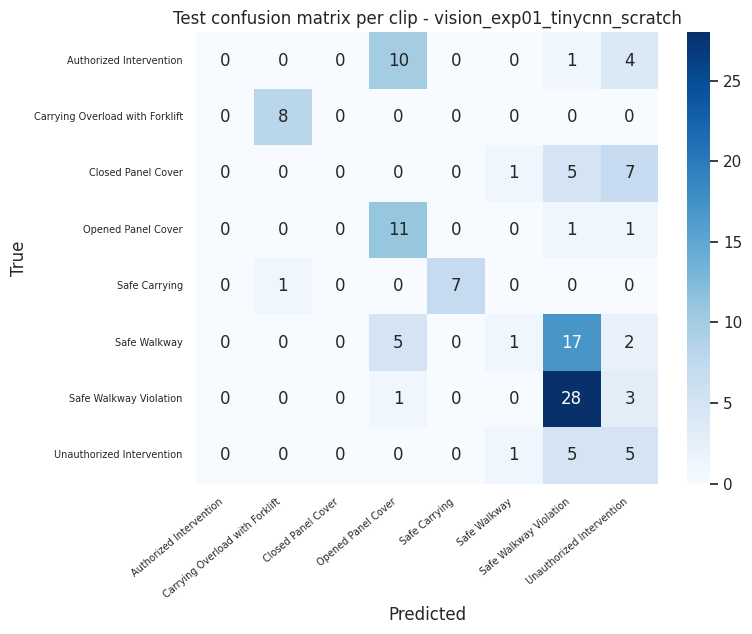

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp01_tinycnn_scratch


In [14]:
run_experiment(
    "vision_exp01_tinycnn_scratch", "Baseline CNN from scratch (no pretrained weights)",
    TinyCNN(NUM_CLASSES), base_loaders, epochs=EPOCHS_SCRATCH, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "TinyCNN", "meaning": "4 conv blocks, random initialisation"},
        {"parameter": "epochs_max", "value": EPOCHS_SCRATCH, "meaning": "Epoch limit (early stopping may end sooner)"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "AdamW learning rate"},
    ],
    extra_meta={"architecture": "TinyCNN", "pretrained": False, "freeze_backbone": False},
)

### 5.2 Experiment 2 - ResNet18, frozen backbone

,value,meaning
parameter,,
architecture,ResNet18 (ImageNet),"Backbone frozen, new linear head"
epochs_max,8,Epoch limit
lr,0.001,Head learning rate


vision_exp02_resnet18_frozen: Transfer learning - ResNet18 (frozen backbone) | epochs <= 8, lr 0.001, device cuda


epoch 1/8:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.2073 | val_loss 0.9514 | val_f1_macro 0.3720 | val_clip_f1_macro 0.3945  *


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


...

epoch 7/8:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 07 | train_loss 0.7863 | val_loss 0.7997 | val_f1_macro 0.5865 | val_clip_f1_macro 0.5971


epoch 8/8:   0%|          | 0/121 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/tor

  epoch 08 | train_loss 0.7850 | val_loss 0.7976 | val_f1_macro 0.6378 | val_clip_f1_macro 0.5866
  kept epoch 5 (val clip macro-F1 0.6294) | test macro-F1 0.5465 | test clip macro-F1 0.5709 | clip unsafe recall 0.9688
                                 precision    recall  f1-score   support

        Authorized Intervention      1.000     0.200     0.333        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      0.583     0.538     0.560        13
             Opened Panel Cover      0.361     1.000     0.531        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.000     0.000     0.000        25
         Safe Walkway Violation      0.658     0.781     0.714        32
      Unauthorized Intervention      0.353     0.545     0.429        11

                       accuracy                          0.560       125
                      macro avg      0.619     0.

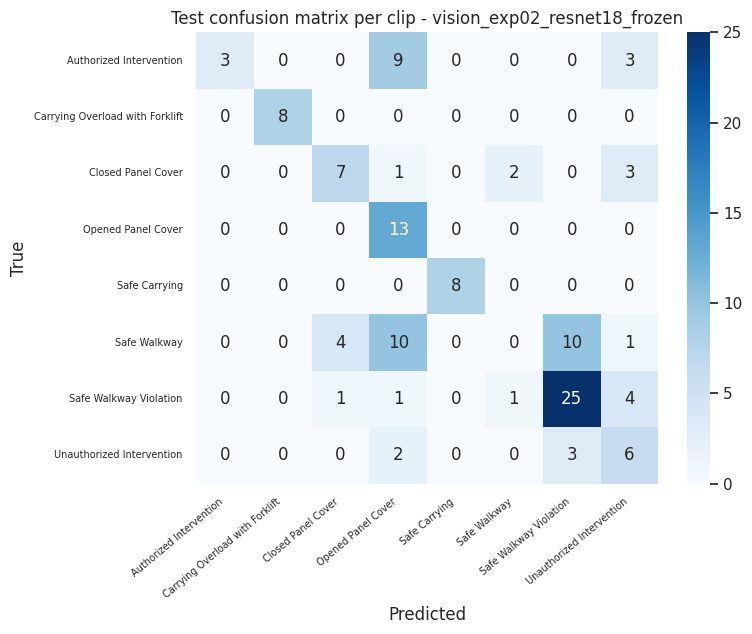

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp02_resnet18_frozen


In [15]:
run_experiment(
    "vision_exp02_resnet18_frozen", "Transfer learning - ResNet18 (frozen backbone)",
    build_resnet18(NUM_CLASSES, freeze_backbone=True), base_loaders, epochs=EPOCHS_FROZEN, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "ResNet18 (ImageNet)", "meaning": "Backbone frozen, new linear head"},
        {"parameter": "epochs_max", "value": EPOCHS_FROZEN, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "Head learning rate"},
    ],
    extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": True},
)

### 5.3 Experiment 3 - ResNet18, full fine-tune

,value,meaning
parameter,,
architecture,ResNet18 (ImageNet),Every layer trainable
epochs_max,20,Epoch limit
lr,0.0001,Low rate to keep the pretrained features


vision_exp03_resnet18_finetune: Fine-tuning - ResNet18 (full network, lower LR) | epochs <= 20, lr 0.0001, device cuda


epoch 1/20:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 01 | train_loss 0.8539 | val_loss 0.6480 | val_f1_macro 0.6403 | val_clip_f1_macro 0.6393  *


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


...

  epoch 09 | train_loss 0.2741 | val_loss 1.0936 | val_f1_macro 0.6751 | val_clip_f1_macro 0.6535


epoch 10/20:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 10 | train_loss 0.2305 | val_loss 1.1859 | val_f1_macro 0.6683 | val_clip_f1_macro 0.6675


epoch 11/20:   0%|          | 0/121 [00:20<?, ?it/s]

  epoch 11 | train_loss 0.2087 | val_loss 1.4220 | val_f1_macro 0.6656 | val_clip_f1_macro 0.6562
  early stop: no better validation clip macro-F1 for 5 epochs
  kept epoch 6 (val clip macro-F1 0.6829) | test macro-F1 0.6290 | test clip macro-F1 0.6392 | clip unsafe recall 0.8594
                                 precision    recall  f1-score   support

        Authorized Intervention      0.667     0.133     0.222        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      0.611     0.846     0.710        13
             Opened Panel Cover      0.409     0.692     0.514        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.550     0.440     0.489        25
         Safe Walkway Violation      0.778     0.656     0.712        32
      Unauthorized Intervention      0.368     0.636     0.467        11

                       accuracy                          0.6

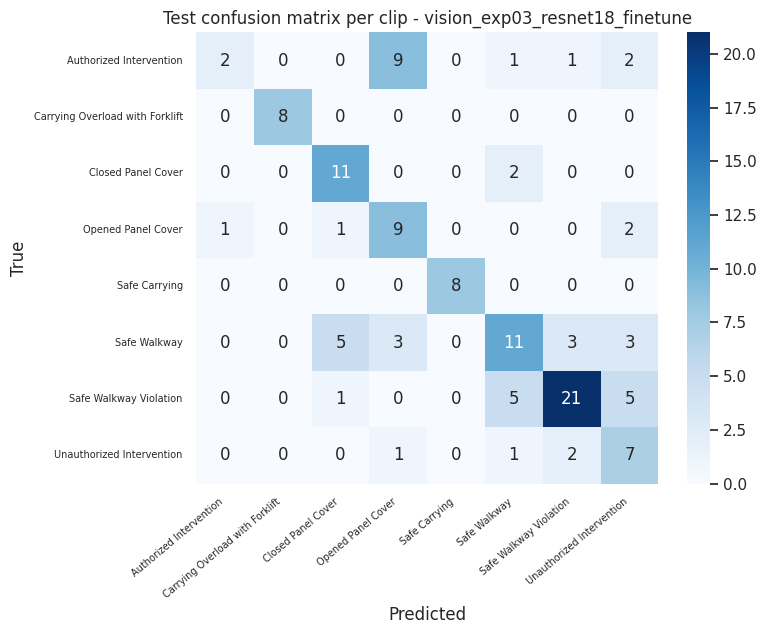

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp03_resnet18_finetune


In [16]:
run_experiment(
    "vision_exp03_resnet18_finetune", "Fine-tuning - ResNet18 (full network, lower LR)",
    build_resnet18(NUM_CLASSES, freeze_backbone=False), base_loaders, epochs=EPOCHS_FINETUNE, lr=LR_FINETUNE,
    hyperparams=[
        {"parameter": "architecture", "value": "ResNet18 (ImageNet)", "meaning": "Every layer trainable"},
        {"parameter": "epochs_max", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_FINETUNE, "meaning": "Low rate to keep the pretrained features"},
    ],
    extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": False},
)

### 5.4 Experiment 4 - EfficientNet-B0, frozen backbone

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 118MB/s] 


,value,meaning
parameter,,
architecture,EfficientNet-B0 (ImageNet),"Backbone frozen, new linear head"
epochs_max,8,Epoch limit
lr,0.001,Head learning rate


vision_exp04_efficientnet_b0_frozen: Transfer learning - EfficientNet-B0 (frozen backbone) | epochs <= 8, lr 0.001, device cuda


epoch 1/8:   0%|          | 0/121 [00:00<?, ?it/s]

...

epoch 7/8:   0%|          | 0/121 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 07 | train_loss 0.7475 | val_loss 0.7133 | val_f1_macro 0.6728 | val_clip_f1_macro 0.6737


epoch 8/8:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 08 | train_loss 0.7449 | val_loss 0.7049 | val_f1_macro 0.6911 | val_clip_f1_macro 0.6855
  kept epoch 4 (val clip macro-F1 0.6862) | test macro-F1 0.5649 | test clip macro-F1 0.5601 | clip unsafe recall 0.9375
                                 precision    recall  f1-score   support

        Authorized Intervention      1.000     0.067     0.125        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      0.857     0.462     0.600        13
             Opened Panel Cover      0.265     1.000     0.419        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.400     0.160     0.229        25
         Safe Walkway Violation      0.697     0.719     0.708        32
      Unauthorized Intervention      0.444     0.364     0.400        11

                       accuracy                          0.536       125
                      macro avg      0.708     0.

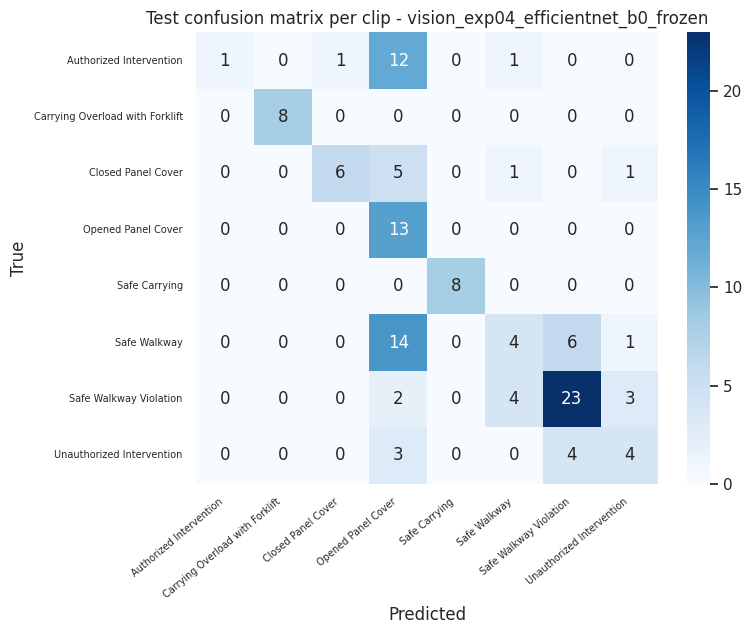

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp04_efficientnet_b0_frozen


In [17]:
run_experiment(
    "vision_exp04_efficientnet_b0_frozen", "Transfer learning - EfficientNet-B0 (frozen backbone)",
    build_efficientnet_b0(NUM_CLASSES, freeze_backbone=True), base_loaders, epochs=EPOCHS_FROZEN, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "EfficientNet-B0 (ImageNet)", "meaning": "Backbone frozen, new linear head"},
        {"parameter": "epochs_max", "value": EPOCHS_FROZEN, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "Head learning rate"},
    ],
    extra_meta={"architecture": "EfficientNet-B0", "pretrained": True, "freeze_backbone": True},
)

### 5.5 Experiment 5 - MobileNetV3-Small, frozen backbone

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 127MB/s]


,value,meaning
parameter,,
architecture,MobileNetV3-Small (ImageNet),"Backbone frozen, new linear head"
epochs_max,8,Epoch limit
lr,0.001,Head learning rate


vision_exp05_mobilenet_v3_small: Edge-friendly - MobileNetV3-Small (frozen backbone) | epochs <= 8, lr 0.001, device cuda


epoch 1/8:   0%|          | 0/121 [00:00<?, ?it/s]

...

  epoch 06 | train_loss 0.6896 | val_loss 0.7003 | val_f1_macro 0.6264 | val_clip_f1_macro 0.6279


epoch 7/8:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 07 | train_loss 0.6834 | val_loss 0.7018 | val_f1_macro 0.6588 | val_clip_f1_macro 0.6633  *


epoch 8/8:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 08 | train_loss 0.6784 | val_loss 0.7003 | val_f1_macro 0.6535 | val_clip_f1_macro 0.6751  *
  kept epoch 8 (val clip macro-F1 0.6751) | test macro-F1 0.6064 | test clip macro-F1 0.5726 | clip unsafe recall 0.9375
                                 precision    recall  f1-score   support

        Authorized Intervention      1.000     0.067     0.125        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      0.562     0.692     0.621        13
             Opened Panel Cover      0.345     0.769     0.476        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.400     0.160     0.229        25
         Safe Walkway Violation      0.686     0.750     0.716        32
      Unauthorized Intervention      0.333     0.545     0.414        11

                       accuracy                          0.560       125
                      macro avg      0.666    

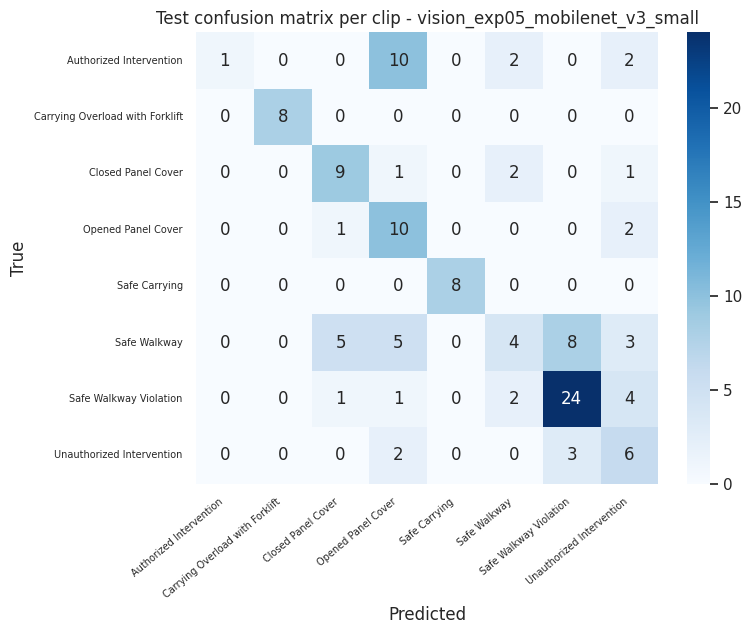

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp05_mobilenet_v3_small


In [18]:
run_experiment(
    "vision_exp05_mobilenet_v3_small", "Edge-friendly - MobileNetV3-Small (frozen backbone)",
    build_mobilenet_v3_small(NUM_CLASSES, freeze_backbone=True), base_loaders, epochs=EPOCHS_FROZEN, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "MobileNetV3-Small (ImageNet)", "meaning": "Backbone frozen, new linear head"},
        {"parameter": "epochs_max", "value": EPOCHS_FROZEN, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "Head learning rate"},
    ],
    extra_meta={"architecture": "MobileNetV3-Small", "pretrained": True, "freeze_backbone": True, "deployment": "edge"},
)

### 5.6 Experiment 6 - EfficientNet-B0, robust fine-tune

The imbalance is countered once, through inverse-frequency class weights in the loss, normalised so the average weight is 1. Resampling the rare classes as well would count the imbalance twice and push the model toward over-predicting them. Strong augmentation imitates other camera positions and lighting.

,train_frames,loss_weight
Authorized Intervention,159,1.666
Carrying Overload with Forklift,328,0.807
Closed Panel Cover,128,2.069
Opened Panel Cover,880,0.301
Safe Carrying,152,1.742
Safe Walkway,335,0.791
Safe Walkway Violation,1204,0.220
Unauthorized Intervention,655,0.404


,value,meaning
parameter,,
architecture,EfficientNet-B0 (ImageNet),Every layer trainable
epochs_max,20,Epoch limit
lr,0.0001,Low rate to keep the pretrained features
loss,class-weighted cross-entropy,"Inverse class frequency, mean weight 1"
augmentation,"crop, flip, colour jitter, rotation",torchvision transforms


vision_exp06_efficientnet_robust: Robust fine-tune - EfficientNet-B0 + class-weighted loss + strong augmentation | epochs <= 20, lr 0.0001, device cuda


epoch 1/20:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.4466 | val_loss 1.0951 | val_f1_macro 0.5521 | val_clip_f1_macro 0.5555  *


...

epoch 6/20:   0%|          | 0/121 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 06 | train_loss 0.6839 | val_loss 1.1127 | val_f1_macro 0.6073 | val_clip_f1_macro 0.5970


epoch 7/20:   0%|          | 0/121 [00:00<?, ?it/s]

  epoch 07 | train_loss 0.6232 | val_loss 1.1356 | val_f1_macro 0.6176 | val_clip_f1_macro 0.6157
  early stop: no better validation clip macro-F1 for 5 epochs
  kept epoch 2 (val clip macro-F1 0.7262) | test macro-F1 0.6533 | test clip macro-F1 0.6529 | clip unsafe recall 0.8125
                                 precision    recall  f1-score   support

        Authorized Intervention      0.647     0.733     0.688        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      0.500     1.000     0.667        13
             Opened Panel Cover      0.444     0.615     0.516        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.500     0.160     0.242        25
         Safe Walkway Violation      0.690     0.625     0.656        32
      Unauthorized Intervention      0.455     0.455     0.455        11

                       accuracy                          0.6

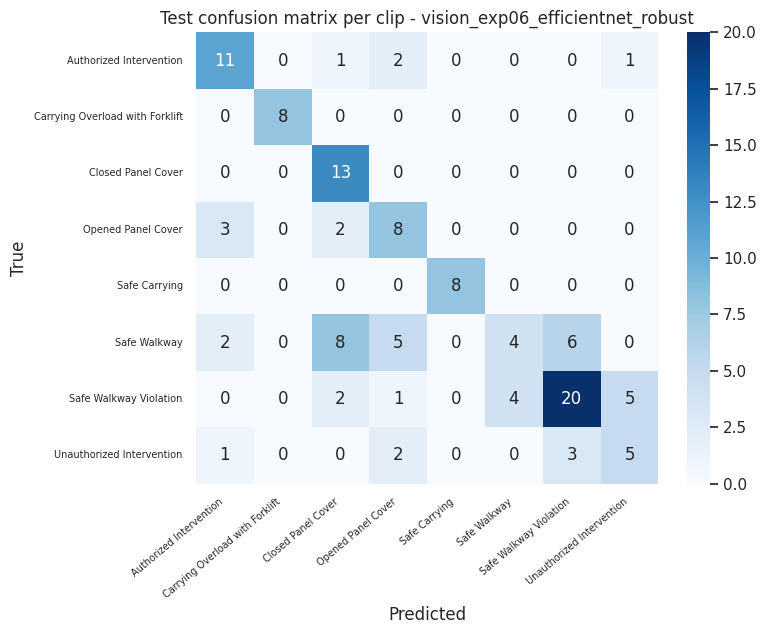

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp06_efficientnet_robust


In [19]:
train_counts = FRAMES["train"]["label_idx"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
inverse = 1.0 / train_counts.clip(lower=1).to_numpy(dtype=np.float32)
class_weights = torch.tensor(inverse / inverse.mean(), dtype=torch.float32)
save_table(pd.DataFrame({"train_frames": train_counts.to_numpy(), "loss_weight": class_weights.numpy().round(3)}, index=CLASS_NAMES), "exp06_class_weights")

run_experiment(
    "vision_exp06_efficientnet_robust", "Robust fine-tune - EfficientNet-B0 + class-weighted loss + strong augmentation",
    build_efficientnet_b0(NUM_CLASSES, freeze_backbone=False), make_loaders(FRAMES, strong_train_tfms),
    epochs=EPOCHS_FINETUNE, lr=LR_FINETUNE, class_weights=class_weights,
    hyperparams=[
        {"parameter": "architecture", "value": "EfficientNet-B0 (ImageNet)", "meaning": "Every layer trainable"},
        {"parameter": "epochs_max", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_FINETUNE, "meaning": "Low rate to keep the pretrained features"},
        {"parameter": "loss", "value": "class-weighted cross-entropy", "meaning": "Inverse class frequency, mean weight 1"},
        {"parameter": "augmentation", "value": "crop, flip, colour jitter, rotation", "meaning": "torchvision transforms"},
    ],
    extra_meta={"architecture": "EfficientNet-B0", "pretrained": True, "freeze_backbone": False,
                "class_weights": class_weights.tolist(), "strong_augmentation": True},
)

### 5.7 Experiment 7 - ConvNeXt-Tiny at 288 pixels

Several classes hinge on small details: an open or closed panel cover, the load on a forklift. 224 pixels from a 1080p frame loses much of that. ConvNeXt-Tiny is a modern convolutional backbone; it is trained at `IMG_SIZE_LARGE` with the class weights and strong augmentation of experiment 6, plus label smoothing, which stops the network from becoming over-confident on a small dataset.

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 216MB/s]


,value,meaning
parameter,,
architecture,ConvNeXt-Tiny (ImageNet),Every layer trainable
img_size,288,Input size
epochs_max,20,Epoch limit
lr,0.0001,Low rate to keep the pretrained features
loss,"class-weighted cross-entropy, label smoothing 0.1",Counters imbalance and over-confidence


vision_exp07_convnext_tiny_288: ConvNeXt-Tiny at 288 px + class weights + strong augmentation + label smoothing | epochs <= 20, lr 0.0001, device cuda


epoch 1/20:   0%|          | 0/241 [00:00<?, ?it/s]

...

epoch 7/20:   0%|          | 0/241 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bf7c360b920>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 07 | train_loss 1.1248 | val_loss 1.8193 | val_f1_macro 0.6725 | val_clip_f1_macro 0.6586


epoch 8/20:   0%|          | 0/241 [00:00<?, ?it/s]

  epoch 08 | train_loss 1.1001 | val_loss 1.8569 | val_f1_macro 0.6717 | val_clip_f1_macro 0.6664
  early stop: no better validation clip macro-F1 for 5 epochs
  kept epoch 3 (val clip macro-F1 0.6790) | test macro-F1 0.6557 | test clip macro-F1 0.6463 | clip unsafe recall 0.8125
                                 precision    recall  f1-score   support

        Authorized Intervention      0.500     0.400     0.444        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      0.542     1.000     0.703        13
             Opened Panel Cover      0.467     0.538     0.500        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.467     0.280     0.350        25
         Safe Walkway Violation      0.719     0.719     0.719        32
      Unauthorized Intervention      0.455     0.455     0.455        11

                       accuracy                          0.6

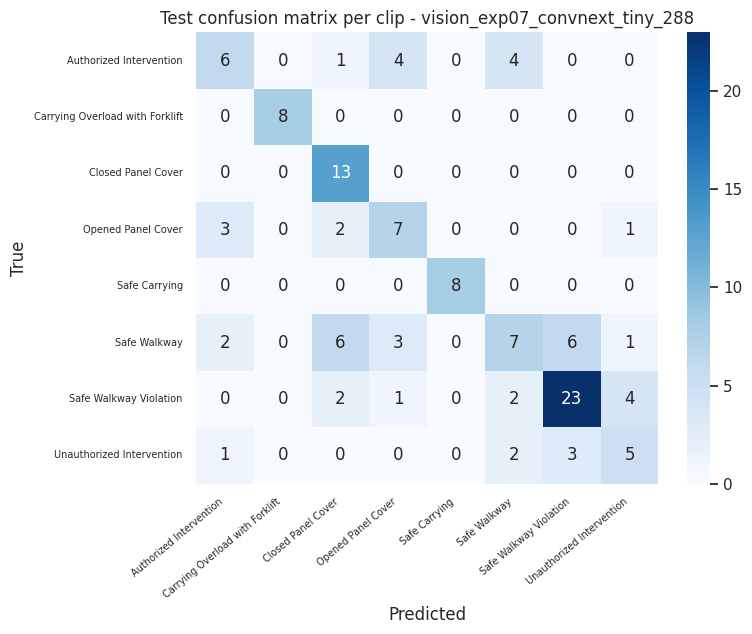

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp07_convnext_tiny_288


In [20]:
large_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE_LARGE + 32, IMG_SIZE_LARGE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE_LARGE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    NORMALIZE,
])
large_eval_tfms = transforms.Compose([transforms.Resize((IMG_SIZE_LARGE, IMG_SIZE_LARGE)), transforms.ToTensor(), NORMALIZE])

convnext = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
convnext.classifier[2] = nn.Linear(convnext.classifier[2].in_features, NUM_CLASSES)

run_experiment(
    "vision_exp07_convnext_tiny_288", "ConvNeXt-Tiny at 288 px + class weights + strong augmentation + label smoothing",
    convnext, make_loaders(FRAMES, large_train_tfms, large_eval_tfms, batch_size=BATCH_SIZE_LARGE),
    epochs=EPOCHS_FINETUNE, lr=LR_FINETUNE, class_weights=class_weights, label_smoothing=LABEL_SMOOTHING,
    hyperparams=[
        {"parameter": "architecture", "value": "ConvNeXt-Tiny (ImageNet)", "meaning": "Every layer trainable"},
        {"parameter": "img_size", "value": IMG_SIZE_LARGE, "meaning": "Input size"},
        {"parameter": "epochs_max", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_FINETUNE, "meaning": "Low rate to keep the pretrained features"},
        {"parameter": "loss", "value": f"class-weighted cross-entropy, label smoothing {LABEL_SMOOTHING}", "meaning": "Counters imbalance and over-confidence"},
    ],
    extra_meta={"architecture": "ConvNeXt-Tiny", "pretrained": True, "freeze_backbone": False, "img_size": IMG_SIZE_LARGE,
                "class_weights": class_weights.tolist(), "label_smoothing": LABEL_SMOOTHING, "strong_augmentation": True},
)

### 5.8 Experiment 8 - R(2+1)D-18 on whole clips

Authorized and unauthorized intervention, or a safe walkway and a violation of it, can look the same in one frame and differ in what the person does over time. R(2+1)D-18 is a video network pretrained on Kinetics-400, a set of human actions. It takes a clip's `MAX_FRAMES_PER_VIDEO` frames in order, at `VIDEO_SIZE` pixels, normalised with the Kinetics statistics.

During training, every frame of a clip gets the same random crop, flip and brightness change, so the motion between frames stays intact. One sample is one clip, so the class weights are recomputed per clip.

Downloading: "https://download.pytorch.org/models/r2plus1d_18-91a641e6.pth" to /root/.cache/torch/hub/checkpoints/r2plus1d_18-91a641e6.pth


100%|██████████| 120M/120M [00:00<00:00, 179MB/s]


,value,meaning
parameter,,
architecture,R(2+1)D-18 (Kinetics-400),Every layer trainable
frames,8,"Frames per clip, in order"
frame_size,160,Frame size
epochs_max,20,Epoch limit
lr,0.0001,Low rate to keep the pretrained features
loss,"class-weighted cross-entropy per clip, label s...",Counters imbalance and over-confidence


vision_exp08_r2plus1d_video: Video model - R(2+1)D-18 (Kinetics-400) on whole clips | epochs <= 20, lr 0.0001, device cuda


epoch 1/20:   0%|          | 0/61 [00:00<?, ?it/s]

...

  epoch 16 | train_loss 0.8960 | val_loss 1.6829 | val_f1_macro 0.6970 | val_clip_f1_macro 0.6970


epoch 17/20:   0%|          | 0/61 [00:00<?, ?it/s]

  epoch 17 | train_loss 0.8917 | val_loss 1.6758 | val_f1_macro 0.7028 | val_clip_f1_macro 0.7028


epoch 18/20:   0%|          | 0/61 [00:00<?, ?it/s]

  epoch 18 | train_loss 0.8904 | val_loss 1.6489 | val_f1_macro 0.7210 | val_clip_f1_macro 0.7210
  early stop: no better validation clip macro-F1 for 5 epochs
  kept epoch 13 (val clip macro-F1 0.7545) | test macro-F1 0.6941 | test clip macro-F1 0.6941 | clip unsafe recall 0.8594
                                 precision    recall  f1-score   support

        Authorized Intervention      0.615     0.533     0.571        15
Carrying Overload with Forklift      1.000     1.000     1.000         8
             Closed Panel Cover      1.000     0.538     0.700        13
             Opened Panel Cover      0.467     0.538     0.500        13
                  Safe Carrying      1.000     1.000     1.000         8
                   Safe Walkway      0.609     0.560     0.583        25
         Safe Walkway Violation      0.636     0.656     0.646        32
      Unauthorized Intervention      0.444     0.727     0.552        11

                       accuracy                          0.

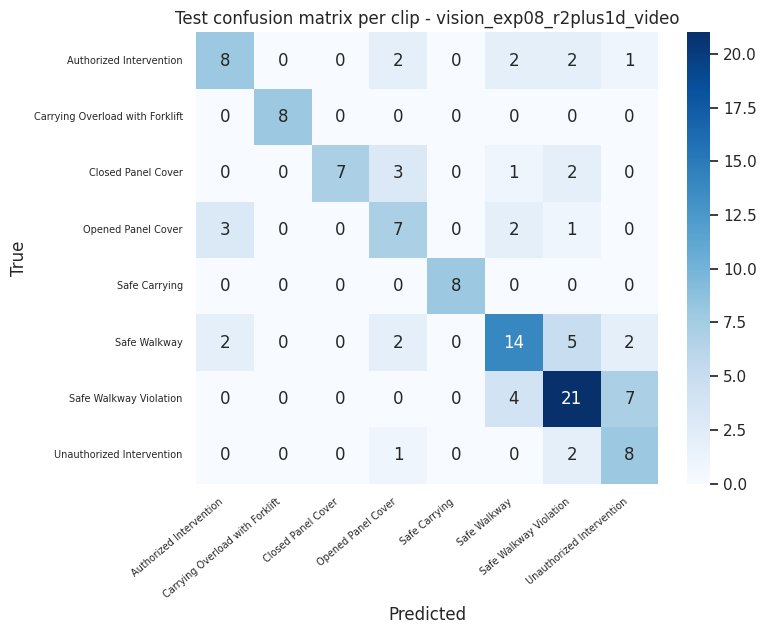

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp08_r2plus1d_video


In [21]:
class ClipDataset(Dataset):
    """All stored frames of a clip, in order, as one (C, T, H, W) tensor."""

    def __init__(self, frames: pd.DataFrame, train: bool):
        self.clips = []
        for video, group in frames.groupby("video", sort=True):
            paths = group.sort_values("relpath")["filepath"].tolist()
            self.clips.append((video, paths, int(group["label_idx"].iloc[0])))
        self.train = train

    def __len__(self) -> int:
        return len(self.clips)

    def __getitem__(self, idx: int):
        _video, paths, label = self.clips[idx]
        images = [Image.open(p).convert("RGB") for p in paths]
        images += [images[-1]] * (MAX_FRAMES_PER_VIDEO - len(images))
        if self.train:
            top, left, height, width = transforms.RandomResizedCrop.get_params(images[0], scale=(0.7, 1.0), ratio=(3 / 4, 4 / 3))
            flip = random.random() < 0.5
            brightness = random.uniform(0.75, 1.25)
        tensors = []
        for image in images[:MAX_FRAMES_PER_VIDEO]:
            if self.train:
                image = TF.resized_crop(image, top, left, height, width, [VIDEO_SIZE, VIDEO_SIZE])
                if flip:
                    image = TF.hflip(image)
                image = TF.adjust_brightness(image, brightness)
            else:
                image = TF.resize(image, [VIDEO_SIZE, VIDEO_SIZE])
            tensors.append(TF.normalize(TF.to_tensor(image), KINETICS_MEAN, KINETICS_STD))
        return torch.stack(tensors, dim=1), label


clip_sets = {split: ClipDataset(frame, train=split == "train") for split, frame in FRAMES.items()}
pin = torch.cuda.is_available()
clip_loaders = {
    split: DataLoader(dataset, batch_size=VIDEO_BATCH_SIZE, shuffle=split == "train", num_workers=NUM_WORKERS, pin_memory=pin,
                      generator=torch.Generator().manual_seed(SEED) if split == "train" else None)
    for split, dataset in clip_sets.items()
}
clip_ids = {split: np.array([clip[0] for clip in dataset.clips]) for split, dataset in clip_sets.items()}

clip_counts = pd.Series([clip[2] for clip in clip_sets["train"].clips]).value_counts().reindex(range(NUM_CLASSES), fill_value=0)
clip_inverse = 1.0 / clip_counts.clip(lower=1).to_numpy(dtype=np.float32)
clip_weights = torch.tensor(clip_inverse / clip_inverse.mean(), dtype=torch.float32)

video_model = models.video.r2plus1d_18(weights=models.video.R2Plus1D_18_Weights.KINETICS400_V1)
video_model.fc = nn.Linear(video_model.fc.in_features, NUM_CLASSES)

run_experiment(
    "vision_exp08_r2plus1d_video", "Video model - R(2+1)D-18 (Kinetics-400) on whole clips",
    video_model, clip_loaders, epochs=EPOCHS_VIDEO, lr=LR_FINETUNE, class_weights=clip_weights,
    clips=clip_ids, label_smoothing=LABEL_SMOOTHING,
    hyperparams=[
        {"parameter": "architecture", "value": "R(2+1)D-18 (Kinetics-400)", "meaning": "Every layer trainable"},
        {"parameter": "frames", "value": MAX_FRAMES_PER_VIDEO, "meaning": "Frames per clip, in order"},
        {"parameter": "frame_size", "value": VIDEO_SIZE, "meaning": "Frame size"},
        {"parameter": "epochs_max", "value": EPOCHS_VIDEO, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_FINETUNE, "meaning": "Low rate to keep the pretrained features"},
        {"parameter": "loss", "value": f"class-weighted cross-entropy per clip, label smoothing {LABEL_SMOOTHING}", "meaning": "Counters imbalance and over-confidence"},
    ],
    extra_meta={"architecture": "R(2+1)D-18", "pretrained": "Kinetics-400", "freeze_backbone": False, "input": "clip",
                "frames": MAX_FRAMES_PER_VIDEO, "frame_size": VIDEO_SIZE,
                "normalization": {"mean": KINETICS_MEAN, "std": KINETICS_STD}, "label_smoothing": LABEL_SMOOTHING},
)

### 6.1 Comparison

The ledger holds one row per experiment. Experiments are ranked by **best validation clip macro-F1**, the only score used to choose. The test columns show how each model does on unseen clips, per clip and, for the image models, per frame. Where the validation and test rankings disagree, remember that the validation set is small: about 85 clips.

,approach,best_val_clip_f1_macro,best_epoch,epochs_run,test_clip_accuracy,test_clip_f1_macro,test_clip_binary_accuracy,test_clip_unsafe_recall,test_clip_unsafe_precision,test_clip_safe_recall,test_accuracy,test_f1_macro,test_f1_weighted,test_binary_accuracy,test_unsafe_recall,test_unsafe_precision,test_safe_recall,lr,elapsed_sec
experiment_id,,,,,,,,,,,,,,,,,,,
vision_exp08_r2plus1d_video,Video model - R(2+1)D-18 (Kinetics-400) on who...,0.7545,13,18,0.648,0.6941,0.776,0.8594,0.7432,0.6885,0.6480,0.6941,0.6520,0.7760,0.8594,0.7432,0.6885,0.0001,474.9318
vision_exp06_efficientnet_robust,Robust fine-tune - EfficientNet-B0 + class-wei...,0.7262,2,7,0.616,0.6529,0.792,0.8125,0.7879,0.7705,0.6167,0.6533,0.5881,0.7968,0.8291,0.7858,0.7629,0.0001,128.2523
vision_exp04_efficientnet_b0_frozen,Transfer learning - EfficientNet-B0 (frozen ba...,0.6862,4,8,0.536,0.5601,0.656,0.9375,0.6061,0.3607,0.5473,0.5649,0.5174,0.6720,0.9214,0.6212,0.4103,0.0010,126.6787
vision_exp03_resnet18_finetune,"Fine-tuning - ResNet18 (full network, lower LR)",0.6829,6,11,0.616,0.6392,0.760,0.8594,0.7237,0.6557,0.6097,0.6290,0.5945,0.7616,0.8448,0.7313,0.6742,0.0001,171.6641
vision_exp07_convnext_tiny_288,ConvNeXt-Tiny at 288 px + class weights + stro...,0.6790,3,8,0.616,0.6463,0.792,0.8125,0.7879,0.7705,0.6227,0.6557,0.6059,0.7968,0.8134,0.7946,0.7794,0.0001,447.6203
vision_exp05_mobilenet_v3_small,Edge-friendly - MobileNetV3-Small (frozen back...,0.6751,8,8,0.560,0.5726,0.728,0.9375,0.6667,0.5082,0.5855,0.6064,0.5624,0.7243,0.9234,0.6667,0.5155,0.0010,146.3945
vision_exp02_resnet18_frozen,Transfer learning - ResNet18 (frozen backbone),0.6294,5,8,0.560,0.5709,0.688,0.9688,0.6263,0.3934,0.5392,0.5465,0.4923,0.6831,0.9568,0.6244,0.3959,0.0010,116.4957
vision_exp01_tinycnn_scratch,Baseline CNN from scratch (no pretrained weights),0.5195,11,12,0.480,0.4285,0.576,0.9844,0.5478,0.1475,0.4859,0.4299,0.3936,0.5875,0.9804,0.5551,0.1753,0.0010,181.5103


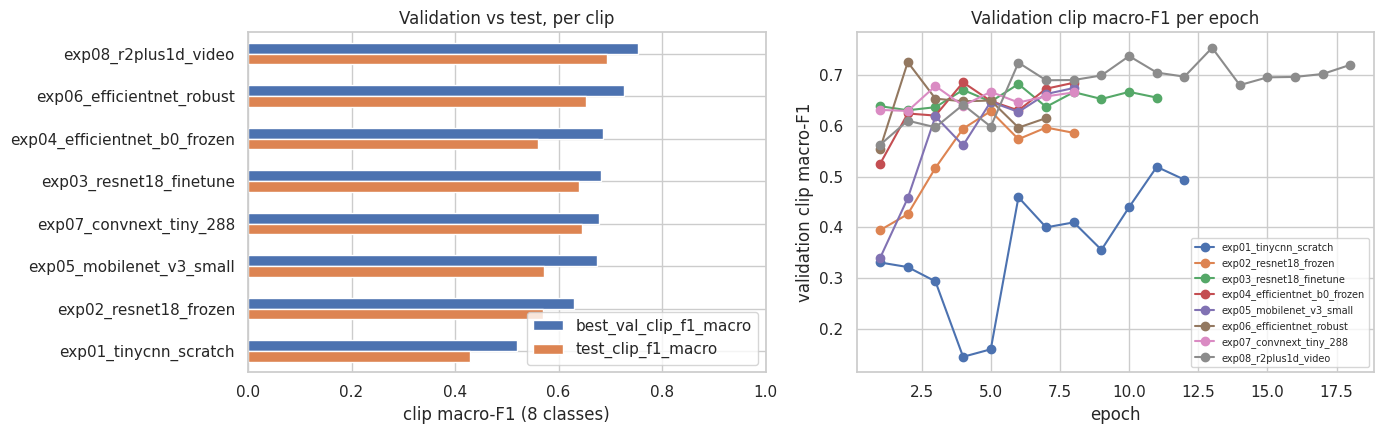

In [22]:
EXPERIMENT_IDS = [
    "vision_exp01_tinycnn_scratch", "vision_exp02_resnet18_frozen", "vision_exp03_resnet18_finetune",
    "vision_exp04_efficientnet_b0_frozen", "vision_exp05_mobilenet_v3_small", "vision_exp06_efficientnet_robust",
    "vision_exp07_convnext_tiny_288", "vision_exp08_r2plus1d_video",
]
ledger = pd.read_csv(LEDGER_PATH)
comparison = ledger[ledger["experiment_id"].isin(EXPERIMENT_IDS)].sort_values("best_val_clip_f1_macro", ascending=False).set_index("experiment_id")
save_table(comparison.drop(columns=["timestamp_utc"]).round(4), "experiment_comparison")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
short = [i.replace("vision_", "") for i in comparison.index]
comparison[["best_val_clip_f1_macro", "test_clip_f1_macro"]].set_axis(short).plot.barh(ax=axes[0])
axes[0].invert_yaxis()
axes[0].set(xlabel="clip macro-F1 (8 classes)", title="Validation vs test, per clip", xlim=(0, 1))
for exp_id, result in EXPERIMENT_RESULTS.items():
    axes[1].plot(result["history"]["epoch"], result["history"]["val_clip_f1_macro"], marker="o", label=exp_id.replace("vision_", ""))
axes[1].set(xlabel="epoch", ylabel="validation clip macro-F1", title="Validation clip macro-F1 per epoch")
axes[1].legend(fontsize=7)
save_figure("experiment_comparison")

### 6.2 Promote the validation winner

The winner's weights are copied to `best.pt` with its metadata and a model card. The test set did not influence the choice.

In [23]:
winner_id = comparison.index[0]
src_dir = MODELS_DIR / winner_id
shutil.copy2(src_dir / "model.pt", MODELS_DIR / "best.pt")
winner_meta = json.loads((src_dir / "metadata.json").read_text())
winner_meta.update({"promoted_from": winner_id, "selection_metric": "best_val_clip_f1_macro", "selection_value": float(comparison.loc[winner_id, "best_val_clip_f1_macro"])})
(MODELS_DIR / "metadata.json").write_text(json.dumps(winner_meta, indent=2, default=to_json_safe))

test = winner_meta["test_clip_metrics"]
(MODELS_DIR / "model_card.md").write_text(f"""# SAMS safe/unsafe behaviour classifier

- **Status:** exploratory; not loaded by the live SAMS services
- **Model:** {winner_id} ({winner_meta['approach']})
- **Dataset:** {HF_REPO}, published train/test split; validation = {VAL_FRACTION:.0%} of each class's training clips
- **Input:** {'whole clip of ' + str(MAX_FRAMES_PER_VIDEO) + ' frames at ' + str(VIDEO_SIZE) + ' px, Kinetics normalisation' if winner_meta.get('input') == 'clip' else 'RGB frames, ImageNet normalisation; class probabilities averaged over a clip'}
- **Classes:** {', '.join(CLASS_NAMES)}
- **Selected on:** validation clip macro-F1 = {winner_meta['selection_value']:.3f} (epoch {winner_meta['best_epoch']})
- **Test per clip, 8 classes:** accuracy {test['accuracy']:.3f}, macro-F1 {test['f1_macro']:.3f}
- **Test per clip, SAFE/UNSAFE:** accuracy {test['binary_accuracy']:.3f}, unsafe recall {test['unsafe_recall']:.3f}, unsafe precision {test['unsafe_precision']:.3f}
- **Limits:** one facility; single frames cannot see context (who is authorised); see Section 7 of notebooks/01_vision_safe_unsafe.ipynb
""")
print("Promoted", winner_id, "to", MODELS_DIR / "best.pt")

Promoted vision_exp08_r2plus1d_video to /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/best.pt


### 6.3 Winner in detail

Per-class F1, per clip, shows which behaviours the winner can and cannot tell apart. The SAFE/UNSAFE table folds the eight-class confusion matrix into the two groups SAMS would act on. A frame counts as caught when the model predicts any unsafe class for an unsafe frame, even if it names the wrong one.

In [24]:
cm = np.array(test["confusion_matrix"])
per_class = pd.DataFrame({
    "group": ["UNSAFE" if c in UNSAFE_CLASSES else "SAFE" for c in CLASS_NAMES],
    "test_clips": cm.sum(axis=1),
    "recall": np.diag(cm) / cm.sum(axis=1).clip(min=1),
    "f1": [test["f1_per_class"][c] for c in CLASS_NAMES],
    "most_confused_with": [CLASS_NAMES[int(np.argmax(np.where(np.arange(NUM_CLASSES) == i, -1, cm[i])))] for i in range(NUM_CLASSES)],
}, index=CLASS_NAMES)
save_table(per_class.sort_values("f1").round(3), "winner_per_class")

is_unsafe = np.isin(np.arange(NUM_CLASSES), UNSAFE_IDX)
binary_cm = pd.DataFrame(
    [[cm[np.ix_(~is_unsafe, ~is_unsafe)].sum(), cm[np.ix_(~is_unsafe, is_unsafe)].sum()],
     [cm[np.ix_(is_unsafe, ~is_unsafe)].sum(), cm[np.ix_(is_unsafe, is_unsafe)].sum()]],
    index=["true SAFE", "true UNSAFE"], columns=["pred SAFE", "pred UNSAFE"],
)
save_table(binary_cm, "winner_safe_unsafe_confusion")
save_table(comparison[["test_clip_binary_accuracy", "test_clip_unsafe_recall", "test_clip_unsafe_precision", "test_clip_safe_recall"]].round(3), "safe_unsafe_by_experiment")

,group,test_clips,recall,f1,most_confused_with
Opened Panel Cover,UNSAFE,13,0.538,0.500,Authorized Intervention
Unauthorized Intervention,UNSAFE,11,0.727,0.552,Safe Walkway Violation
Authorized Intervention,SAFE,15,0.533,0.571,Opened Panel Cover
Safe Walkway,SAFE,25,0.560,0.583,Safe Walkway Violation
Safe Walkway Violation,UNSAFE,32,0.656,0.646,Unauthorized Intervention
Closed Panel Cover,SAFE,13,0.538,0.700,Opened Panel Cover
Carrying Overload with Forklift,UNSAFE,8,1.000,1.000,Authorized Intervention
Safe Carrying,SAFE,8,1.000,1.000,Authorized Intervention


,pred SAFE,pred UNSAFE
true SAFE,42,19
true UNSAFE,9,55


,test_clip_binary_accuracy,test_clip_unsafe_recall,test_clip_unsafe_precision,test_clip_safe_recall
experiment_id,,,,
vision_exp08_r2plus1d_video,0.776,0.859,0.743,0.689
vision_exp06_efficientnet_robust,0.792,0.812,0.788,0.770
vision_exp04_efficientnet_b0_frozen,0.656,0.938,0.606,0.361
vision_exp03_resnet18_finetune,0.760,0.859,0.724,0.656
vision_exp07_convnext_tiny_288,0.792,0.812,0.788,0.770
vision_exp05_mobilenet_v3_small,0.728,0.938,0.667,0.508
vision_exp02_resnet18_frozen,0.688,0.969,0.626,0.393
vision_exp01_tinycnn_scratch,0.576,0.984,0.548,0.148


PosixPath('/content/drive/MyDrive/SAMS/results/vision/safe_unsafe/safe_unsafe_by_experiment.csv')